In [1]:
import os, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

BASE = os.path.expanduser("~/Desktop/prototype")
STATIC = ["RecordID","Age","Gender","Height","ICUType","Weight"]

In [2]:
import glob, pandas as pd

def load_set(name):
    files = glob.glob(f"{BASE}/set-{name}/**/*.txt", recursive=True)
    print(f"set-{name}: {len(files)} files")
    rows = []
    for f in files:
        d = pd.read_csv(f)
        rid = int(d.loc[d.Parameter == "RecordID", "Value"].iloc[0])
        d["RecordID"] = rid
        d["set"] = name
        rows.append(d)
    return pd.concat(rows, ignore_index=True)

SETS = ["a", "b", "c"]
raw = pd.concat([load_set(s) for s in SETS], ignore_index=True)

t = raw["Time"].str.split(":", expand=True).astype(int)
raw["minutes"] = t[0] * 60 + t[1]
raw["hour"] = raw["minutes"] / 60

out = pd.concat(
    [pd.read_csv(f"{BASE}/Outcomes-{s}.txt").assign(set=s) for s in SETS],
    ignore_index=True,
)

print(raw.shape, out.shape)
print(raw.groupby("set")["RecordID"].nunique())
print(out.groupby("set").size())
print("RecordIDs appearing in >1 set:", (raw.groupby("RecordID")["set"].nunique() > 1).sum())

set-a: 4000 files
set-b: 4000 files
set-c: 4000 files
(5285818, 7) (12000, 7)
set
a    4000
b    4000
c    4000
Name: RecordID, dtype: int64
set
a    4000
b    4000
c    4000
dtype: int64
RecordIDs appearing in >1 set: 0


In [3]:
STATIC = ["RecordID","Age","Gender","Height","ICUType","Weight"]

# Static variables: rows at 00:00 only
static = (raw[raw.Parameter.isin(STATIC[1:]) & (raw.minutes == 0)]
          .pivot_table(index="RecordID", columns="Parameter", values="Value", aggfunc="first")
          .reset_index())

# -1 means missing in static fields
for c in ["Age","Gender","Height","ICUType","Weight"]:
    static.loc[static[c] < 0, c] = np.nan
static.loc[static.Height < 100, "Height"] = np.nan                       # implausible heights
static.loc[(static.Weight < 20) | (static.Weight > 300), "Weight"] = np.nan

# Time-series: everything except static fields
ts = raw[~raw.Parameter.isin(STATIC)].copy()
ts = ts[ts.Value != -1]                      # -1 = missing in time-series too

# Plausibility ranges to drop sensor/entry errors
ranges = {"HR":(0,300),"Temp":(25,45),"SysABP":(20,300),"DiasABP":(10,250),"MAP":(20,250),
          "NISysABP":(30,300),"NIDiasABP":(10,250),"NIMAP":(20,250),"RespRate":(0,100),
          "SaO2":(40,100),"FiO2":(0.21,1.0),"pH":(6.5,8.0),"PaO2":(10,700),"PaCO2":(10,150),
          "GCS":(3,15),"Lactate":(0.1,40),"Glucose":(10,1500),"Creatinine":(0.1,30)}
n_before = len(ts)
for p,(lo,hi) in ranges.items():
    m = ts.Parameter == p
    ts = ts[~m | ts.Value.between(lo,hi)]
print(f"Dropped {n_before-len(ts):,} implausible/missing rows ({100*(n_before-len(ts))/n_before:.2f}%)")

df_out = out.merge(static, on="RecordID", how="left")
df_out["died"] = df_out["In-hospital_death"]

print(ts.Parameter.nunique(), "time-series variables;", df_out.shape[0], "patients")
print(df_out.shape)
print(df_out.isna().mean().round(3).sort_values(ascending=False).head(8))
df_out.head()

Dropped 5,878 implausible/missing rows (0.12%)
36 time-series variables; 12000 patients
(12000, 13)
Height            0.479
Weight            0.084
Gender            0.001
SAPS-I            0.000
RecordID          0.000
Survival          0.000
Length_of_stay    0.000
SOFA              0.000
dtype: float64


,RecordID,SAPS-I,SOFA,Length_of_stay,Survival,In-hospital_death,set,Age,Gender,Height,ICUType,Weight,died
0,132539,6,1,5,-1,0,a,54.0,0.0,NaN,4.0,NaN,0
1,132540,16,8,8,-1,0,a,76.0,1.0,175.3,2.0,76.0,0
2,132541,21,11,19,-1,0,a,44.0,0.0,NaN,3.0,56.7,0
3,132543,7,1,9,575,0,a,68.0,1.0,180.3,3.0,84.6,0
4,132545,17,2,4,918,0,a,88.0,0.0,NaN,3.0,NaN,0


     count     mean
set                
a     4000  0.13850
b     4000  0.14200
c     4000  0.14625
Overall mortality: 0.142


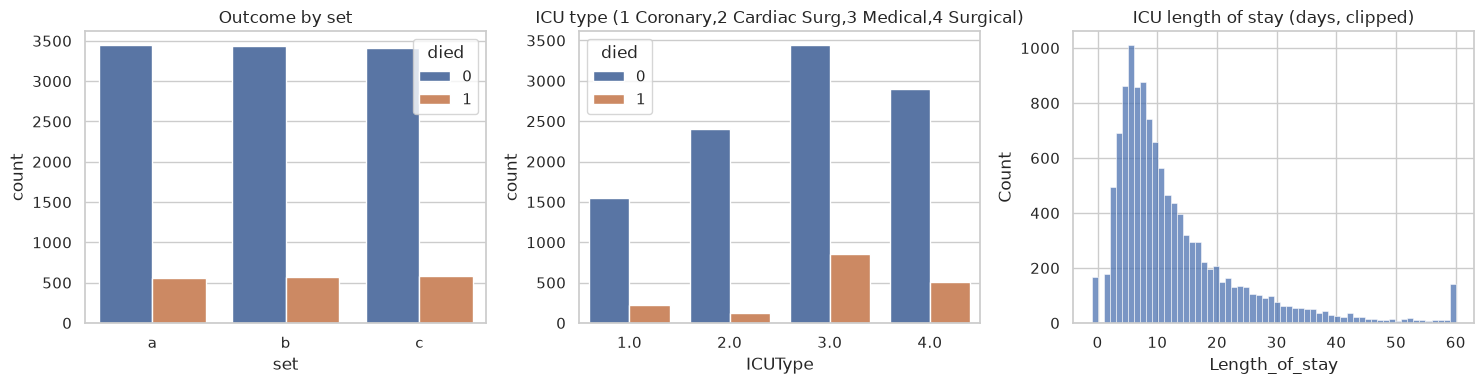

In [4]:
print(df_out.groupby("set")["died"].agg(["count","mean"]))
print("Overall mortality:", df_out.died.mean().round(3))

fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.countplot(data=df_out, x="set", hue="died", ax=ax[0]); ax[0].set_title("Outcome by set")
sns.countplot(data=df_out, x="ICUType", hue="died", ax=ax[1]); ax[1].set_title("ICU type (1 Coronary,2 Cardiac Surg,3 Medical,4 Surgical)")
sns.histplot(df_out["Length_of_stay"].clip(upper=60), bins=60, ax=ax[2]); ax[2].set_title("ICU length of stay (days, clipped)")
plt.tight_layout()

         count      mean
ICUType                 
1.0       1769  0.126625
2.0       2530  0.048617
3.0       4293  0.198463
4.0       3408  0.149061
                  count        mean        std    min    25%    50%    75%  \
Age             12000.0   64.529333  17.175677   15.0   53.0   67.0   78.0   
Height           6257.0  169.956577  15.134540  121.9  162.6  170.2  177.8   
Weight          10997.0   81.207530  23.527223   21.7   65.7   78.0   92.0   
SAPS-I          12000.0   14.308917   6.043346   -1.0   11.0   15.0   18.0   
SOFA            12000.0    6.405917   4.220225   -1.0    3.0    6.0    9.0   
Length_of_stay  12000.0   13.420167  12.812649   -1.0    6.0   10.0   16.0   

                  max  
Age              90.0  
Height          462.3  
Weight          300.0  
SAPS-I           38.0  
SOFA             22.0  
Length_of_stay  295.0  


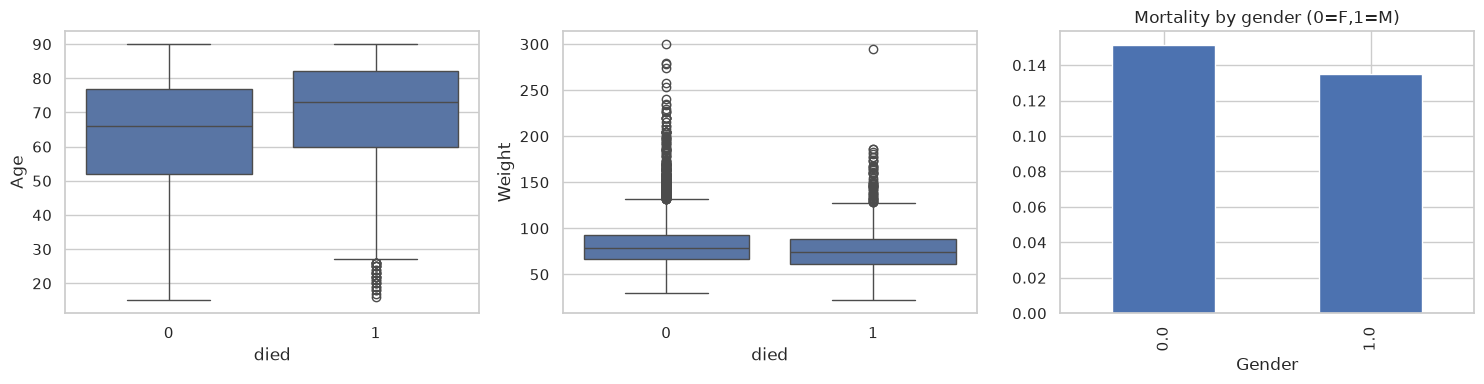

In [5]:
fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.boxplot(data=df_out, x="died", y="Age", ax=ax[0])
sns.boxplot(data=df_out, x="died", y="Weight", ax=ax[1])
df_out.groupby("Gender")["died"].mean().plot.bar(ax=ax[2], title="Mortality by gender (0=F,1=M)")
plt.tight_layout()

print(df_out.groupby("ICUType")["died"].agg(["count","mean"]))
print(df_out[["Age","Height","Weight","SAPS-I","SOFA","Length_of_stay"]].describe().T)

,n_obs,n_patients,pct_patients_with_var,obs_per_patient
Parameter,,,,
TroponinI,1175,565,4.71,2.08
Cholesterol,995,948,7.90,1.05
TroponinT,6254,2637,21.98,2.37
RespRate,165435,3328,27.73,49.71
Albumin,7249,4871,40.59,1.49
ALP,9441,5097,42.48,1.85
ALT,9710,5213,43.44,1.86
AST,9712,5214,43.45,1.86
Bilirubin,9807,5214,43.45,1.88


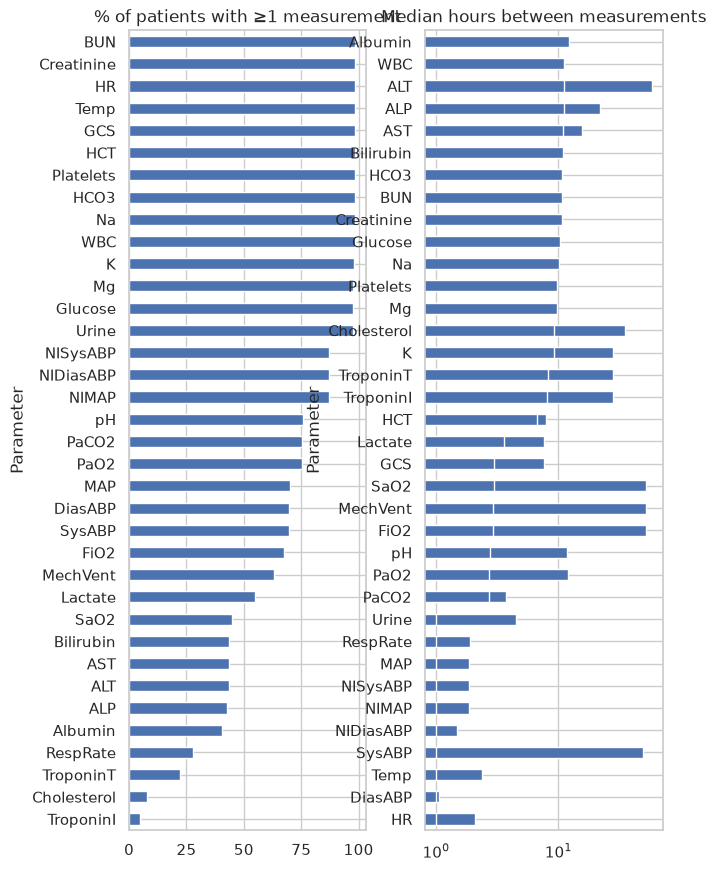

In [6]:
n_pat = df_out.RecordID.nunique()

summary = (ts.groupby("Parameter")
             .agg(n_obs=("Value","size"), n_patients=("RecordID","nunique")))
summary["pct_patients_with_var"] = 100*summary.n_patients/n_pat
summary["obs_per_patient"] = summary.n_obs/summary.n_patients
summary = summary.sort_values("pct_patients_with_var")
display(summary.round(2))

fig, ax = plt.subplots(1,2, figsize=(14,8))
summary.pct_patients_with_var.plot.barh(ax=ax[0], title="% of patients with ≥1 measurement")
summary.obs_per_patient.plot.barh(ax=ax[1], logx=True, title="Mean measurements per patient (48h, log)")
plt.tight_layout()

# Median gap between consecutive measurements per variable
ts_sorted = ts.sort_values(["RecordID","Parameter","minutes"])
ts_sorted["gap_h"] = ts_sorted.groupby(["RecordID","Parameter"])["minutes"].diff()/60
gap = ts_sorted.groupby("Parameter")["gap_h"].median().sort_values()
gap.plot.barh(figsize=(6,9), title="Median hours between measurements"); plt.show()

,n_obs,n_patients,pct_patients_with_var,obs_per_patient
Parameter,,,,
TroponinI,1175,565,4.71,2.08
Cholesterol,995,948,7.90,1.05
TroponinT,6254,2637,21.98,2.37
RespRate,165435,3328,27.73,49.71
Albumin,7249,4871,40.59,1.49
ALP,9441,5097,42.48,1.85
ALT,9710,5213,43.44,1.86
AST,9712,5214,43.45,1.86
Bilirubin,9807,5214,43.45,1.88


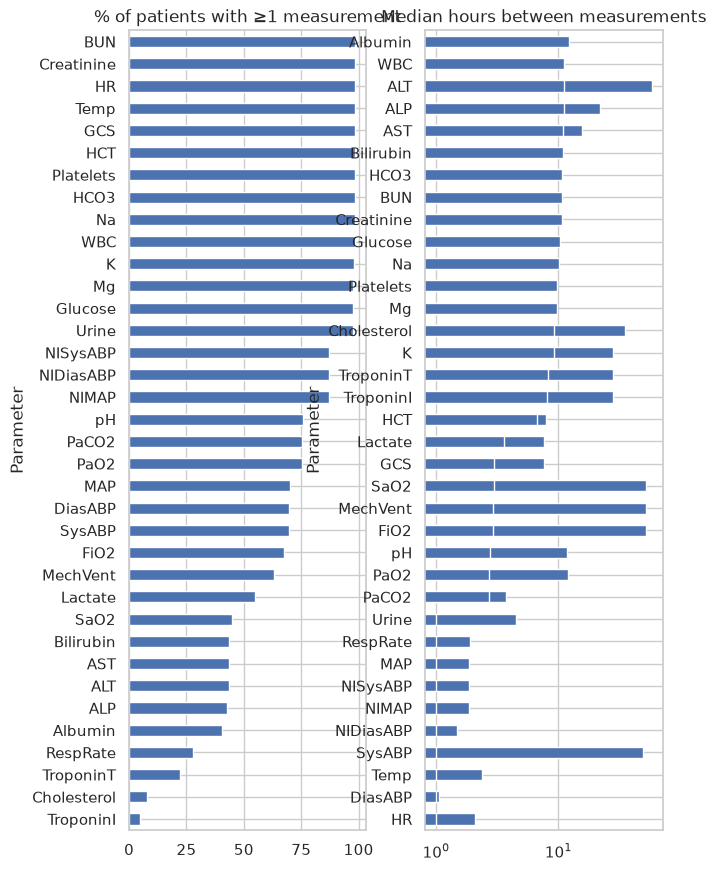

In [7]:
n_pat = df_out.RecordID.nunique()

summary = (ts.groupby("Parameter")
             .agg(n_obs=("Value","size"), n_patients=("RecordID","nunique")))
summary["pct_patients_with_var"] = 100*summary.n_patients/n_pat
summary["obs_per_patient"] = summary.n_obs/summary.n_patients
summary = summary.sort_values("pct_patients_with_var")
display(summary.round(2))

fig, ax = plt.subplots(1,2, figsize=(14,8))
summary.pct_patients_with_var.plot.barh(ax=ax[0], title="% of patients with ≥1 measurement")
summary.obs_per_patient.plot.barh(ax=ax[1], logx=True, title="Mean measurements per patient (48h, log)")
plt.tight_layout()

# Median gap between consecutive measurements per variable
ts_sorted = ts.sort_values(["RecordID","Parameter","minutes"])
ts_sorted["gap_h"] = ts_sorted.groupby(["RecordID","Parameter"])["minutes"].diff()/60
gap = ts_sorted.groupby("Parameter")["gap_h"].median().sort_values()
gap.plot.barh(figsize=(6,9), title="Median hours between measurements"); plt.show()

,n_obs,n_patients,pct_patients_with_var,obs_per_patient
Parameter,,,,
TroponinI,1175,565,4.71,2.08
Cholesterol,995,948,7.90,1.05
TroponinT,6254,2637,21.98,2.37
RespRate,165435,3328,27.73,49.71
Albumin,7249,4871,40.59,1.49
ALP,9441,5097,42.48,1.85
ALT,9710,5213,43.44,1.86
AST,9712,5214,43.45,1.86
Bilirubin,9807,5214,43.45,1.88


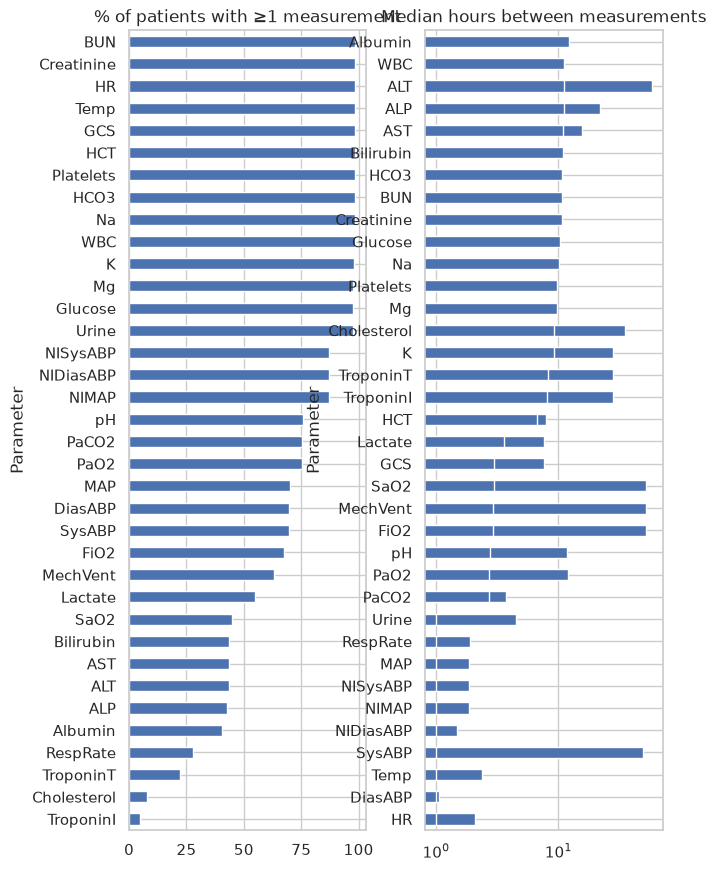

In [8]:
n_pat = df_out.RecordID.nunique()

summary = (ts.groupby("Parameter")
             .agg(n_obs=("Value","size"), n_patients=("RecordID","nunique")))
summary["pct_patients_with_var"] = 100*summary.n_patients/n_pat
summary["obs_per_patient"] = summary.n_obs/summary.n_patients
summary = summary.sort_values("pct_patients_with_var")
display(summary.round(2))

fig, ax = plt.subplots(1,2, figsize=(14,8))
summary.pct_patients_with_var.plot.barh(ax=ax[0], title="% of patients with ≥1 measurement")
summary.obs_per_patient.plot.barh(ax=ax[1], logx=True, title="Mean measurements per patient (48h, log)")
plt.tight_layout()

# Median gap between consecutive measurements per variable
ts_sorted = ts.sort_values(["RecordID","Parameter","minutes"])
ts_sorted["gap_h"] = ts_sorted.groupby(["RecordID","Parameter"])["minutes"].diff()/60
gap = ts_sorted.groupby("Parameter")["gap_h"].median().sort_values()
gap.plot.barh(figsize=(6,9), title="Median hours between measurements"); plt.show()

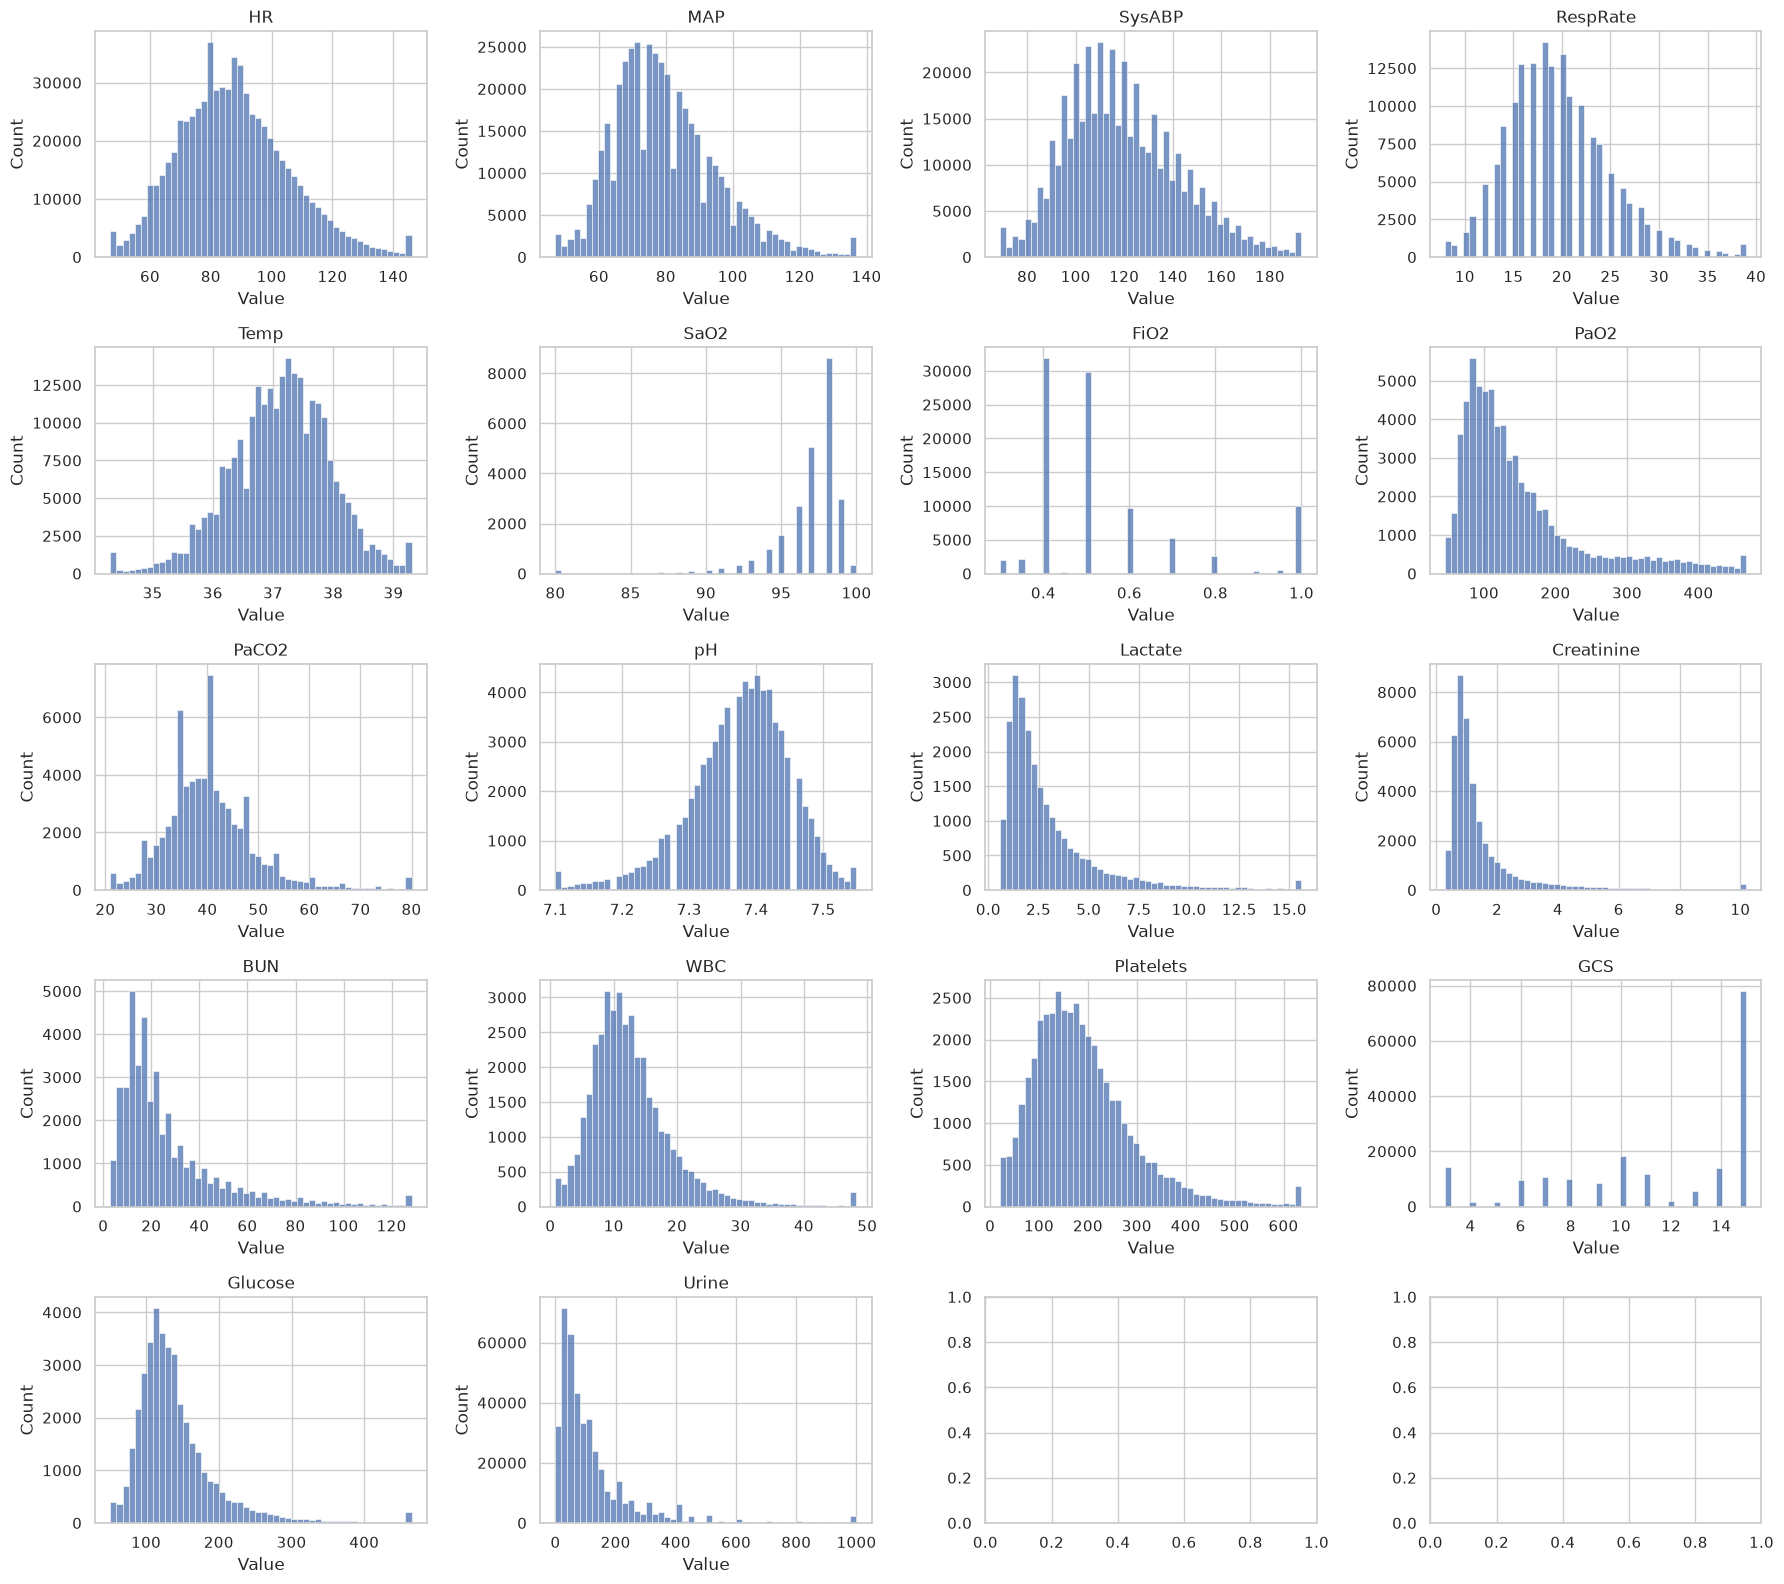

In [9]:
vars_ = ["HR","MAP","SysABP","RespRate","Temp","SaO2","FiO2","PaO2","PaCO2","pH",
         "Lactate","Creatinine","BUN","WBC","Platelets","GCS","Glucose","Urine"]
fig, axes = plt.subplots(5,4, figsize=(18,16)); axes=axes.ravel()
for i,v in enumerate(vars_):
    s = ts.loc[ts.Parameter==v,"Value"]
    sns.histplot(s.clip(s.quantile(.005), s.quantile(.995)), bins=50, ax=axes[i]); axes[i].set_title(v)
plt.tight_layout()

In [10]:
agg = (ts.groupby(["RecordID","Parameter"])["Value"]
         .agg(["first","last","min","max","mean","count"]).reset_index())
wide = agg.pivot(index="RecordID", columns="Parameter")
wide.columns = [f"{p}_{stat}" for stat,p in wide.columns]
wide = wide.reset_index()
feat = df_out.merge(wide, on="RecordID", how="left")

# Univariate separation: AUROC of each feature vs death
from sklearn.metrics import roc_auc_score
res = []
for c in feat.columns:
    if c.endswith(("_first","_last","_min","_max","_mean")):
        d = feat[[c,"died"]].dropna()
        if d.died.nunique()==2 and len(d)>300:
            a = roc_auc_score(d.died, d[c])
            res.append((c, max(a,1-a), len(d)))
uni = pd.DataFrame(res, columns=["feature","auroc","n"]).sort_values("auroc", ascending=False)
display(uni.head(25))

,feature,auroc,n
46,GCS_last,0.755903,11815
154,GCS_mean,0.703717,11815
177,Urine_mean,0.688202,11690
118,GCS_max,0.685114,11815
40,BUN_last,0.681094,11817
76,BUN_min,0.674208,11817
148,BUN_mean,0.673672,11817
141,Urine_max,0.670736,11690
112,BUN_max,0.669140,11817
4,BUN_first,0.657289,11817


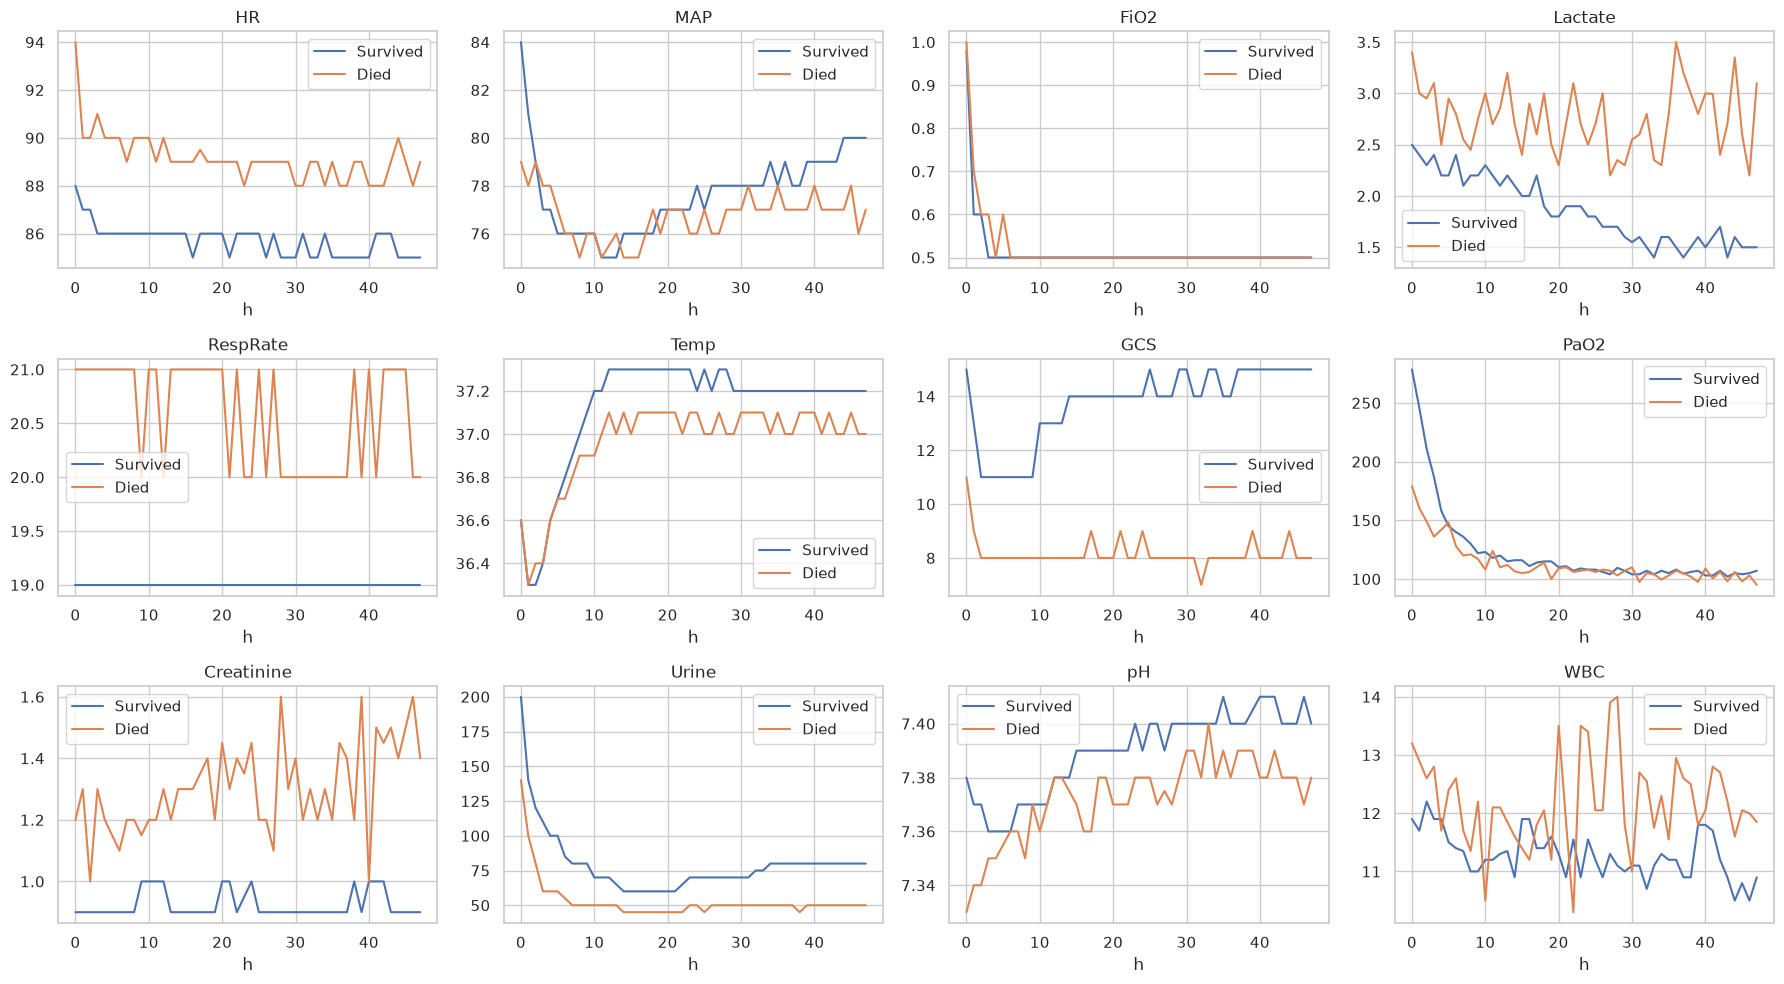

In [11]:
# Hourly median per group
ts = ts.merge(df_out[["RecordID","died"]], on="RecordID")
ts["h"] = (ts.minutes//60).clip(upper=47)

key = ["HR","MAP","FiO2","Lactate","RespRate","Temp","GCS","PaO2","Creatinine","Urine","pH","WBC"]
fig, axes = plt.subplots(3,4, figsize=(18,10)); axes=axes.ravel()
for i,v in enumerate(key):
    g = ts[ts.Parameter==v].groupby(["h","died"])["Value"].median().unstack()
    g.plot(ax=axes[i], title=v); axes[i].legend(["Survived","Died"])
plt.tight_layout()

           count      mean
ever_vent                 
0.0         4419  0.102286
1.0         7581  0.165545


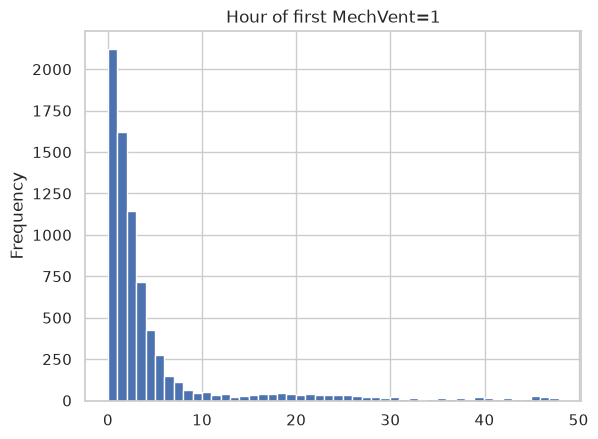

Parameter
TroponinI        4.9
Cholesterol      5.9
TroponinT       20.9
Albumin         40.7
ALP             42.7
ALT             43.5
AST             43.5
Bilirubin       43.6
SaO2            61.1
Lactate         67.7
NIMAP           84.2
NIDiasABP       84.2
NISysABP        84.3
SysABP          89.1
DiasABP         89.1
MAP             89.2
FiO2            96.4
PaO2            97.0
PaCO2           97.0
pH              97.0
Glucose         97.5
K               97.9
Mg              98.0
Na              98.5
WBC             98.5
HCO3            98.6
Platelets       98.7
HCT             98.7
BUN             98.8
Creatinine      98.8
Urine           99.2
HR             100.0
GCS            100.0
Temp           100.0
MechVent       100.0
Name: RecordID, dtype: float64


In [12]:
vent = ts[(ts.Parameter=="MechVent")].groupby("RecordID")["Value"].max()
df_out["ever_vent"] = df_out.RecordID.map(vent).fillna(0)
print(df_out.groupby("ever_vent")["died"].agg(["count","mean"]))

# first-vent timing
first_vent = ts[(ts.Parameter=="MechVent")&(ts.Value==1)].groupby("RecordID")["minutes"].min()/60
first_vent.plot.hist(bins=48, title="Hour of first MechVent=1"); plt.show()

# Missingness of key vent variables within the ventilated cohort
vids = df_out.loc[df_out.ever_vent==1,"RecordID"]
sub = ts[ts.RecordID.isin(vids)]
print((sub.groupby("Parameter").RecordID.nunique()/len(vids)*100).sort_values().round(1))

<Axes: title={'center': 'Median age (h) of last-known lab value'}, xlabel='h'>

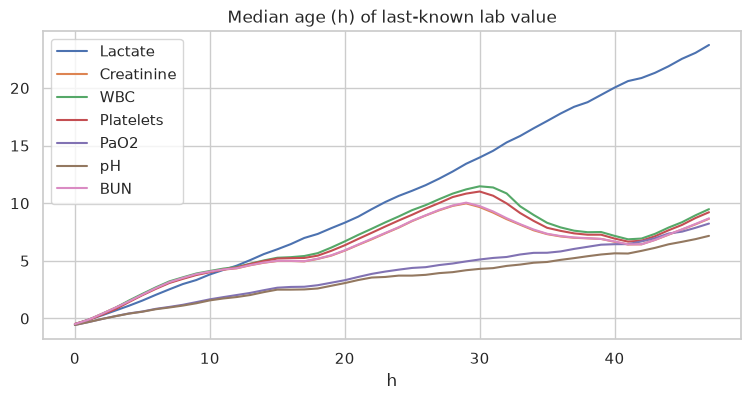

In [13]:
# For each patient/hour, age of last lactate/creatinine/etc.
labs = ["Lactate","Creatinine","WBC","Platelets","PaO2","pH","BUN"]
grid = pd.MultiIndex.from_product([df_out.RecordID, range(48)], names=["RecordID","h"])
stale = {}
for v in labs:
    m = ts[ts.Parameter==v][["RecordID","minutes"]].copy()
    m["t"] = m.minutes/60
    last_seen = (m.groupby(["RecordID", m.t.astype(int).clip(upper=47)]).t.max()
                   .reindex(grid).groupby(level=0).ffill())
    age = pd.Series(grid.get_level_values("h"), index=grid) - last_seen
    stale[v] = age
st = pd.DataFrame(stale)
st.describe().T[["mean","50%","75%","max"]]
st.clip(upper=48).median(level="h") if False else st.groupby(level="h").median().plot(figsize=(9,4), title="Median age (h) of last-known lab value")

In [14]:
from sklearn.metrics import roc_auc_score
for s in ["SAPS-I","SOFA"]:
    d = df_out[[s,"died"]].dropna(); d = d[d[s]>=0]
    print(s, "AUROC =", round(roc_auc_score(d.died, d[s]),3))

SAPS-I AUROC = 0.66
SOFA AUROC = 0.638


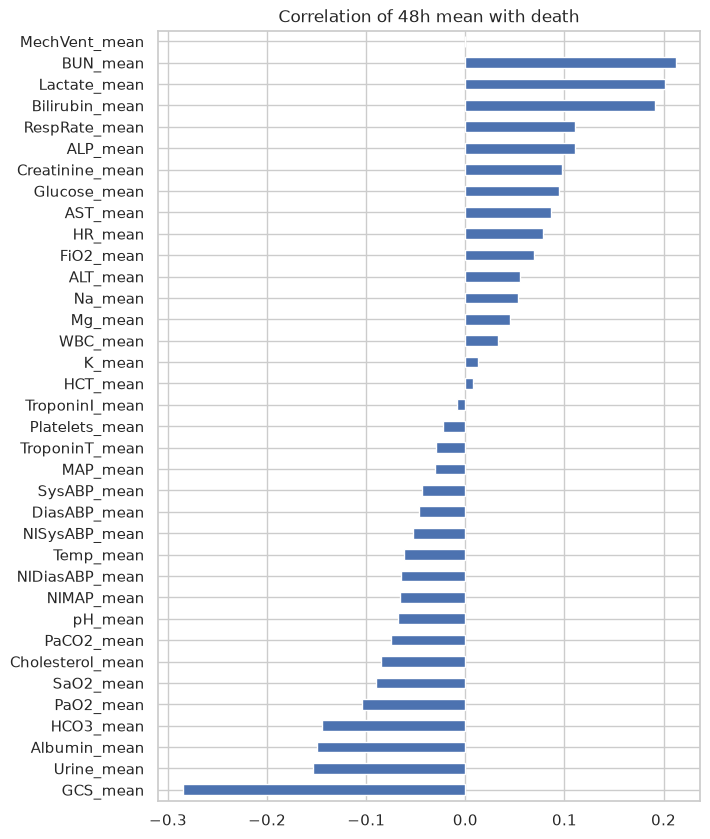

In [15]:
cols = [c for c in feat.columns if c.endswith("_mean")]
corr = feat[cols+["died"]].corr()["died"].drop("died").sort_values()
corr.plot.barh(figsize=(7,10), title="Correlation of 48h mean with death")

feat.to_parquet(f"{BASE}/patient_level_features.parquet")   # save for modeling
ts.to_parquet(f"{BASE}/timeseries_long.parquet")

In [16]:
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

ts = ts.sort_values(["RecordID","Parameter","minutes"]).reset_index(drop=True)

def landmark_table(T):
    d = ts[ts.minutes <= T*60]
    g = d.groupby(["RecordID","Parameter"])
    a = g.agg(last=("Value","last"), mean=("Value","mean"), mn=("Value","min"),
              mx=("Value","max"), n=("Value","size"), t_last=("minutes","max"))
    a["stale_h"] = T - a.t_last/60                      # hours since last measured
    w = (d[d.minutes > (T-6)*60].groupby(["RecordID","Parameter"])
           .agg(w_first=("Value","first"), w_last=("Value","last"),
                t0=("minutes","min"), t1=("minutes","max"), w_mean=("Value","mean")))
    w["slope6"] = (w.w_last - w.w_first) / ((w.t1 - w.t0)/60).where(w.t1 > w.t0)
    f = a.drop(columns="t_last").join(w[["slope6","w_mean"]]).unstack("Parameter")
    f.columns = [f"{p}_{s}" for s, p in f.columns]
    f = f.reset_index()

    cohort = df_out.loc[df_out.Length_of_stay >= T/24,
                        ["RecordID","set","died","SAPS-I","Age","Gender","ICUType","Weight"]]
    tbl = cohort.merge(f, on="RecordID", how="left")
    n_cols = [c for c in tbl.columns if c.endswith("_n")]
    tbl[n_cols] = tbl[n_cols].fillna(0)
    tbl["SAPS-I"] = tbl["SAPS-I"].replace(-1, np.nan)
    return tbl

tables = {T: landmark_table(T) for T in [12, 24, 36]}

def metrics(y, p):
    return dict(AUROC=roc_auc_score(y,p), AUPRC=average_precision_score(y,p), Brier=brier_score_loss(y,p))

meta = ["RecordID","set","died","SAPS-I"]
rows = []
for T, tbl in tables.items():
    tr, te = tbl[tbl.set.isin(["a","b"])], tbl[tbl.set == "c"]
    full = [c for c in tbl.columns if c not in meta]
    nostale = [c for c in full if not c.endswith("_stale_h")]

    lr = make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression(max_iter=1000))
    lr.fit(tr[["SAPS-I"]], tr.died)
    rows.append(dict(T=T, model="SAPS-I logreg", n_test=len(te), prev=te.died.mean(),
                     **metrics(te.died, lr.predict_proba(te[["SAPS-I"]])[:,1])))

    for name, cols in [("LGBM without staleness", nostale), ("LGBM with staleness", full)]:
        m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.6,
                               random_state=0, verbose=-1)
        m.fit(tr[cols], tr.died)
        rows.append(dict(T=T, model=name, n_test=len(te), prev=te.died.mean(),
                         **metrics(te.died, m.predict_proba(te[cols])[:,1])))

results = pd.DataFrame(rows).round(3)
display(results)

,T,model,n_test,prev,AUROC,AUPRC,Brier
0,12,SAPS-I logreg,3947,0.148,0.651,0.249,0.121
1,12,LGBM without staleness,3947,0.148,0.832,0.454,0.102
2,12,LGBM with staleness,3947,0.148,0.830,0.454,0.102
3,24,SAPS-I logreg,3947,0.148,0.651,0.249,0.121
4,24,LGBM without staleness,3947,0.148,0.845,0.490,0.098
5,24,LGBM with staleness,3947,0.148,0.847,0.493,0.098
6,36,SAPS-I logreg,3945,0.148,0.650,0.248,0.121
7,36,LGBM without staleness,3945,0.148,0.865,0.564,0.091
8,36,LGBM with staleness,3945,0.148,0.868,0.577,0.090


T=12h  staleness effect on AUROC: -0.0019  95% CI [-0.0053, +0.0010]
T=12h  staleness effect on AUPRC: -0.0056  95% CI [-0.0148, +0.0042]
T=24h  staleness effect on AUROC: +0.0014  95% CI [-0.0018, +0.0044]
T=24h  staleness effect on AUPRC: +0.0001  95% CI [-0.0101, +0.0095]
T=36h  staleness effect on AUROC: +0.0019  95% CI [-0.0005, +0.0043]
T=36h  staleness effect on AUPRC: +0.0092  95% CI [+0.0019, +0.0167]


AUROC                AUPRC              
T                   12     24     36     12     24     36
model                                                    
last value only  0.824  0.840  0.862  0.444  0.493  0.542
no staleness     0.834  0.848  0.868  0.465  0.497  0.573
static only      0.743  0.743  0.741  0.324  0.324  0.323
with staleness   0.833  0.849  0.869  0.460  0.497  0.582

Text(0.5, 1.0, 'Calibration, T=24h, set c')

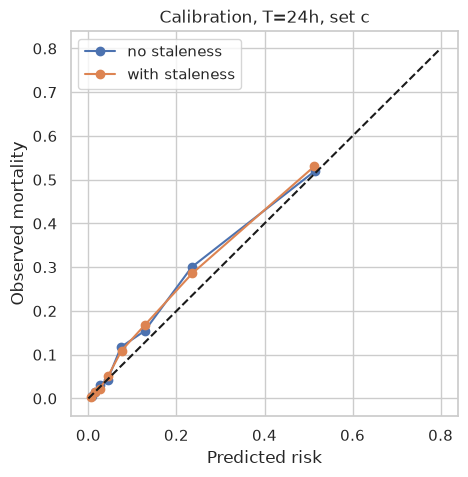

In [17]:
from sklearn.calibration import calibration_curve

def fit_predict(tr, te, cols, seed=0):
    m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.6,
                           random_state=seed, verbose=-1)
    m.fit(tr[cols], tr.died)
    return m.predict_proba(te[cols])[:,1], m

static_cols = ["Age","Gender","ICUType","Weight","SAPS-I"]
rng = np.random.default_rng(0)
B = 1000
summary, store = [], {}

for T, tbl in tables.items():
    tr, te = tbl[tbl.set.isin(["a","b"])], tbl[tbl.set=="c"].reset_index(drop=True)
    full = [c for c in tbl.columns if c not in meta]
    nostale = [c for c in full if not c.endswith("_stale_h")]
    lastonly = [c for c in nostale if c.endswith("_last")] + ["Age","Gender","ICUType","Weight"]
    variants = {"static only": static_cols, "last value only": lastonly,
                "no staleness": nostale, "with staleness": full}
    # average 3 seeds to reduce training noise
    P = {k: np.mean([fit_predict(tr, te, c, s)[0] for s in range(3)], axis=0)
         for k, c in variants.items()}
    store[T] = (te, P)

    y = te.died.values
    for k, p in P.items():
        summary.append(dict(T=T, model=k, AUROC=roc_auc_score(y,p), AUPRC=average_precision_score(y,p)))

    # paired bootstrap: with vs without staleness
    d_auc, d_pr = [], []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max(): continue
        d_auc.append(roc_auc_score(y[i], P["with staleness"][i]) - roc_auc_score(y[i], P["no staleness"][i]))
        d_pr.append(average_precision_score(y[i], P["with staleness"][i]) - average_precision_score(y[i], P["no staleness"][i]))
    for n, d in [("AUROC", d_auc), ("AUPRC", d_pr)]:
        lo, hi = np.percentile(d, [2.5, 97.5])
        print(f"T={T}h  staleness effect on {n}: {np.mean(d):+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")

display(pd.DataFrame(summary).pivot(index="model", columns="T", values=["AUROC","AUPRC"]).round(3))

# Calibration at T=24 (relevant to your alarm-fatigue target)
te, P = store[24]
fig, ax = plt.subplots(figsize=(5,5))
for k in ["no staleness", "with staleness"]:
    fx, fy = calibration_curve(te.died, P[k], n_bins=8, strategy="quantile")
    ax.plot(fy, fx, "o-", label=k)
ax.plot([0,0.8],[0,0.8],"k--"); ax.set_xlabel("Predicted risk"); ax.set_ylabel("Observed mortality")
ax.legend(); ax.set_title("Calibration, T=24h, set c")

In [18]:
def avg_pred(tr, te, cols, seeds=3):
    return np.mean([fit_predict(tr, te, cols, s)[0] for s in range(seeds)], axis=0)

def boot_diff(y, p_new, p_ref, B=1000, seed=0):
    rng = np.random.default_rng(seed)
    da, dp = [], []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max(): continue
        da.append(roc_auc_score(y[i], p_new[i]) - roc_auc_score(y[i], p_ref[i]))
        dp.append(average_precision_score(y[i], p_new[i]) - average_precision_score(y[i], p_ref[i]))
    return [(np.mean(d), *np.percentile(d, [2.5, 97.5])) for d in (da, dp)]

vent_tables, vent_summary = {}, []
for T, tbl in tables.items():
    vids = ts.loc[(ts.Parameter == "MechVent") & (ts.Value == 1) & (ts.minutes <= T*60), "RecordID"].unique()
    vt = tbl[tbl.RecordID.isin(vids)].reset_index(drop=True)
    vent_tables[T] = vt
    tr = vt[vt.set.isin(["a", "b"])]
    te = vt[vt.set == "c"].reset_index(drop=True)
    y = te.died.values
    print(f"T={T}h  ventilated: train n={len(tr)}, test n={len(te)}, test mortality={y.mean():.3f}")

    full = [c for c in vt.columns if c not in meta]
    nostale = [c for c in full if not c.endswith("_stale_h")]
    lastonly = [c for c in nostale if c.endswith("_last")] + ["Age", "Gender", "ICUType", "Weight"]
    variants = {"static only": static_cols, "last value only": lastonly,
                "no staleness": nostale, "with staleness": full}

    lr = make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression(max_iter=1000))
    lr.fit(tr[["SAPS-I"]], tr.died)
    p = lr.predict_proba(te[["SAPS-I"]])[:, 1]
    vent_summary.append(dict(T=T, model="SAPS-I logreg", AUROC=roc_auc_score(y, p), AUPRC=average_precision_score(y, p)))

    P = {}
    for k, cols in variants.items():
        P[k] = avg_pred(tr, te, cols)
        vent_summary.append(dict(T=T, model=k, AUROC=roc_auc_score(y, P[k]), AUPRC=average_precision_score(y, P[k])))

    (a_m, a_lo, a_hi), (p_m, p_lo, p_hi) = boot_diff(y, P["with staleness"], P["no staleness"])
    print(f"   staleness effect  AUROC {a_m:+.4f} [{a_lo:+.4f}, {a_hi:+.4f}]   AUPRC {p_m:+.4f} [{p_lo:+.4f}, {p_hi:+.4f}]")

display(pd.DataFrame(vent_summary).pivot(index="model", columns="T", values=["AUROC", "AUPRC"]).round(3))

T=12h  ventilated: train n=4443, test n=2244, test mortality=0.170
   staleness effect  AUROC -0.0027 [-0.0075, +0.0017]   AUPRC -0.0024 [-0.0151, +0.0116]
T=24h  ventilated: train n=4725, test n=2373, test mortality=0.171
   staleness effect  AUROC -0.0049 [-0.0083, -0.0013]   AUPRC -0.0081 [-0.0199, +0.0040]
T=36h  ventilated: train n=4870, test n=2443, test mortality=0.172
   staleness effect  AUROC -0.0007 [-0.0034, +0.0021]   AUPRC +0.0009 [-0.0087, +0.0107]


AUROC                AUPRC              
T                   12     24     36     12     24     36
model                                                    
SAPS-I logreg    0.633  0.630  0.626  0.270  0.272  0.269
last value only  0.820  0.841  0.869  0.477  0.528  0.598
no staleness     0.839  0.852  0.874  0.502  0.550  0.624
static only      0.767  0.756  0.755  0.364  0.356  0.362
with staleness   0.836  0.847  0.874  0.499  0.542  0.625

In [19]:
LABS = ["Lactate","PaO2","PaCO2","pH","Creatinine","BUN","WBC","Platelets","HCO3","Glucose",
        "K","Na","Mg","HCT","SaO2","Albumin","ALP","ALT","AST","Bilirubin","TroponinT"]
SUFFIX = ("last","mean","mn","mx","slope6","w_mean")

def mask_old(df, X):
    df = df.copy()
    for lab in LABS:
        s = f"{lab}_stale_h"
        if s not in df: continue
        old = df[s] > X
        cols = [f"{lab}_{k}" for k in SUFFIX if f"{lab}_{k}" in df]
        df.loc[old, cols] = np.nan
    return df

def n_lab_last(df):
    return df[[f"{l}_last" for l in LABS if f"{l}_last" in df]].notna().sum().sum()

SOURCE = vent_tables        # switch to `tables` to run on all patients
mask_rows = []
for T, tbl in SOURCE.items():
    cols = [c for c in tbl.columns if c not in meta and not c.endswith("_stale_h")]
    te_raw = tbl[tbl.set == "c"].reset_index(drop=True)
    y = te_raw.died.values
    base_n = n_lab_last(te_raw)

    P_ref = avg_pred(tbl[tbl.set.isin(["a","b"])], te_raw, cols)
    mask_rows.append(dict(T=T, X="none (plain forward-fill)", pct_labs_masked=0.0,
                          AUROC=roc_auc_score(y, P_ref), AUPRC=average_precision_score(y, P_ref)))

    for X in [6, 12, 24]:
        m = mask_old(tbl, X)
        tr, te = m[m.set.isin(["a","b"])], m[m.set == "c"].reset_index(drop=True)
        P = avg_pred(tr, te, cols)
        (a_m, a_lo, a_hi), (p_m, p_lo, p_hi) = boot_diff(y, P, P_ref, B=500)
        mask_rows.append(dict(T=T, X=f"mask > {X}h", pct_labs_masked=100*(1 - n_lab_last(te)/base_n),
                              AUROC=roc_auc_score(y, P), AUPRC=average_precision_score(y, P),
                              dAUROC=a_m, dAUROC_CI=f"[{a_lo:+.4f}, {a_hi:+.4f}]",
                              dAUPRC=p_m, dAUPRC_CI=f"[{p_lo:+.4f}, {p_hi:+.4f}]"))

display(pd.DataFrame(mask_rows).round(4))

,T,X,pct_labs_masked,AUROC,AUPRC,dAUROC,dAUROC_CI,dAUPRC,dAUPRC_CI
0,12,none (plain forward-fill),0.0000,0.8392,0.5017,NaN,NaN,NaN,NaN
1,12,mask > 6h,35.7821,0.8292,0.4831,-0.0101,"[-0.0178, -0.0025]",-0.0183,"[-0.0392, -0.0002]"
2,12,mask > 12h,0.0000,0.8392,0.5017,0.0000,"[+0.0000, +0.0000]",0.0000,"[+0.0000, +0.0000]"
3,12,mask > 24h,0.0000,0.8392,0.5017,0.0000,"[+0.0000, +0.0000]",0.0000,"[+0.0000, +0.0000]"
4,24,none (plain forward-fill),0.0000,0.8518,0.5498,NaN,NaN,NaN,NaN
5,24,mask > 6h,62.3049,0.8417,0.5042,-0.0101,"[-0.0182, -0.0022]",-0.0448,"[-0.0646, -0.0246]"
6,24,mask > 12h,29.4069,0.8472,0.5238,-0.0045,"[-0.0112, +0.0020]",-0.0249,"[-0.0441, -0.0069]"
7,24,mask > 24h,0.0000,0.8518,0.5498,0.0000,"[+0.0000, +0.0000]",0.0000,"[+0.0000, +0.0000]"
8,36,none (plain forward-fill),0.0000,0.8742,0.6237,NaN,NaN,NaN,NaN
9,36,mask > 6h,62.2041,0.8636,0.6057,-0.0107,"[-0.0164, -0.0050]",-0.0181,"[-0.0373, +0.0007]"


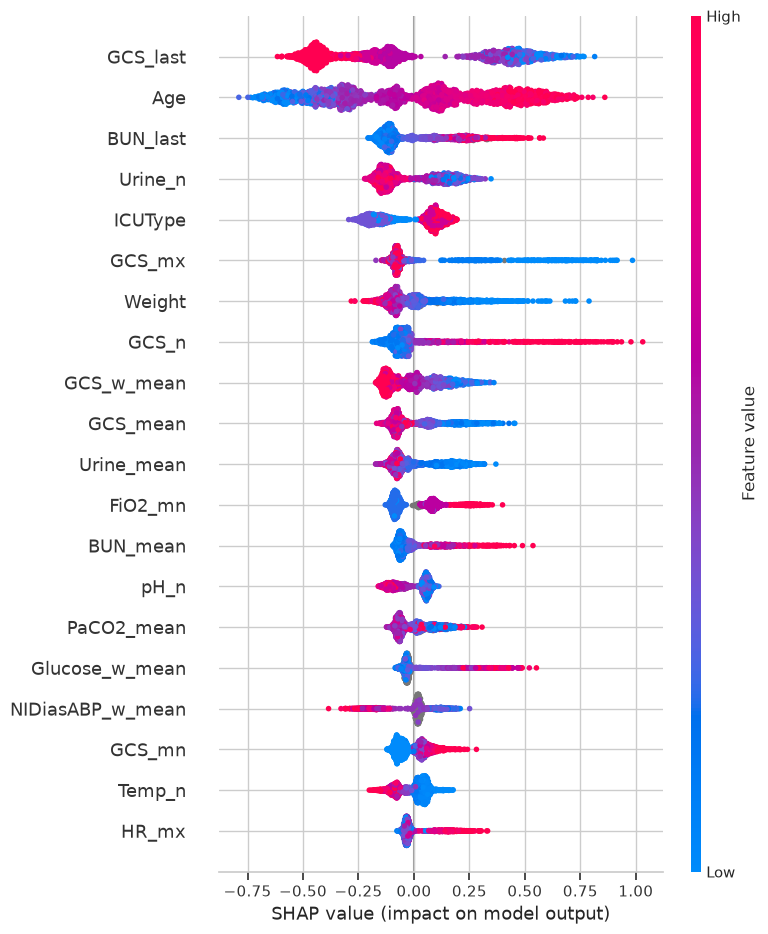

--- Highest-risk patients ---
Patient 160171: 96% in-hospital mortality risk at 24h. Drivers: GCS latest = 3 (raises risk); ALP highest = 1.13e+03 (raises risk); Age = 45 (lowers risk) | actual outcome: died
Patient 162538: 93% in-hospital mortality risk at 24h. Drivers: ALP highest = 644 (raises risk); GCS latest = 7 (raises risk); HR highest = 164 (raises risk) | actual outcome: died
Patient 161293: 93% in-hospital mortality risk at 24h. Drivers: GCS latest = 3 (raises risk); Bilirubin latest = 36.6 (raises risk); BUN latest = 51 (raises risk) | actual outcome: died
Patient 162995: 90% in-hospital mortality risk at 24h. Drivers: Age = 84 (raises risk); GCS latest = 7 (raises risk); GCS no. of measurements = 24 (raises risk) | actual outcome: survived
Patient 162368: 89% in-hospital mortality risk at 24h. Drivers: GCS no. of measurements = 22 (raises risk); GCS highest = 5 (raises risk); GCS latest = 5 (raises risk) | actual outcome: died

--- Mid-risk patients ---
Patient 153000: 42%

In [21]:
import shap

T = 24
vt = vent_tables[T]
tr = vt[vt.set.isin(["a", "b"])]
te = vt[vt.set == "c"].reset_index(drop=True)
cols = [c for c in vt.columns if c not in meta and not c.endswith("_stale_h")]

p, m = fit_predict(tr, te, cols, seed=0)
risk = p
sv = shap.TreeExplainer(m).shap_values(te[cols])
if isinstance(sv, list): sv = sv[1]
sv = np.asarray(sv)
if sv.ndim == 3: sv = sv[:, :, 1]

# Global view
shap.summary_plot(sv, te[cols], max_display=20, show=True)

# Readable names
SUF = [("_slope6", "6h trend"), ("_w_mean", "6h mean"), ("_last", "latest"),
       ("_mean", "mean so far"), ("_mn", "lowest"), ("_mx", "highest"), ("_n", "no. of measurements")]
def readable(c):
    for s, lab in SUF:
        if c.endswith(s):
            return f"{c[:-len(s)]} {lab}"
    return c

def explain(i, k=3):
    top = np.argsort(-np.abs(sv[i]))[:k]
    parts = [f"{readable(cols[j])} = {te.loc[i, cols[j]]:.3g} ({'raises' if sv[i][j] > 0 else 'lowers'} risk)"
             for j in top]
    return f"Patient {te.RecordID[i]}: {risk[i]:.0%} in-hospital mortality risk at {T}h. Drivers: " + "; ".join(parts)

print("--- Highest-risk patients ---")
for i in np.argsort(-risk)[:5]:
    print(explain(i), "| actual outcome:", "died" if te.died[i] else "survived")

print("\n--- Mid-risk patients ---")
mid = np.where((risk > 0.25) & (risk < 0.45))[0][:3]
for i in mid:
    print(explain(i), "| actual outcome:", "died" if te.died[i] else "survived")

In [22]:
import re
SUF = ["_slope6","_w_mean","_last","_mean","_mn","_mx","_n"]
def base(c):
    for s in SUF:
        if c.endswith(s): return c[:-len(s)]
    return c

def explain2(i, k=3):
    contrib = {}
    for j, c in enumerate(cols):
        if c.endswith("_n"): continue            # hide charting-intensity features
        contrib[base(c)] = contrib.get(base(c), 0) + sv[i][j]
    top = sorted(contrib.items(), key=lambda kv: -abs(kv[1]))[:k]
    parts = []
    for v, s in top:
        val = te.loc[i, f"{v}_last"] if f"{v}_last" in te else te.loc[i, v]
        age = te.loc[i, f"{v}_stale_h"] if f"{v}_stale_h" in te else np.nan
        when = f", measured {age:.0f}h ago" if age == age and age >= 3 else ""
        parts.append(f"{v} {val:.3g}{when} ({'raises' if s > 0 else 'lowers'} risk)")
    return f"Patient {te.RecordID[i]}: {risk[i]:.0%} risk. Drivers: " + "; ".join(parts)

for i in np.argsort(-risk)[:5]:
    print(explain2(i), "| actual:", "died" if te.died[i] else "survived")

Patient 160171: 96% risk. Drivers: ALP 695 (raises risk); GCS 3, measured 4h ago (raises risk); Lactate 15.5 (raises risk) | actual: died
Patient 162538: 93% risk. Drivers: ALP 394 (raises risk); HR 136 (raises risk); GCS 7 (raises risk) | actual: died
Patient 161293: 93% risk. Drivers: GCS 3, measured 3h ago (raises risk); Bilirubin 36.6, measured 6h ago (raises risk); Lactate 10.6, measured 11h ago (raises risk) | actual: died
Patient 162995: 90% risk. Drivers: BUN 83 (raises risk); Urine 0 (raises risk); GCS 7 (raises risk) | actual: survived
Patient 162368: 89% risk. Drivers: GCS 5 (raises risk); Age 80 (raises risk); PaCO2 33, measured 5h ago (raises risk) | actual: died


In [23]:
print(ts[ts.Parameter.isin(["ALP","Bilirubin","ALT","AST"])].groupby("Parameter").Value.describe().round(1))
vt = vent_tables[24]
print(vt.groupby(vt["ALP_last"].notna())["died"].agg(["count","mean"]))

            count   mean     std  min   25%   50%    75%      max
Parameter                                                        
ALP        9441.0  120.1   175.1  8.0  59.0  82.0  124.0   4695.0
ALT        9710.0  362.9  1132.8  1.0  20.2  42.0  147.0  16920.0
AST        9712.0  505.2  1649.1  4.0  30.0  62.0  208.2  36400.0
Bilirubin  9807.0    2.9     5.8  0.0   0.5   0.9    2.4     82.8
          count      mean
ALP_last                 
False      4456  0.127244
True       2642  0.232021


In [24]:
LIVER = ["ALP","ALT","AST","Bilirubin","Albumin"]
liver_rows = []
for T, vt in vent_tables.items():
    tr = vt[vt.set.isin(["a","b"])]
    te = vt[vt.set == "c"].reset_index(drop=True)
    y = te.died.values
    full = [c for c in vt.columns if c not in meta and not c.endswith("_stale_h")]
    noliver = [c for c in full if base(c) not in LIVER]
    nocount = [c for c in full if not c.endswith("_n")]
    nocount_noliver = [c for c in noliver if not c.endswith("_n")]

    P = {k: avg_pred(tr, te, c) for k, c in
         {"all features": full, "no liver panel": noliver,
          "no counts": nocount, "no counts, no liver": nocount_noliver}.items()}
    for k, p in P.items():
        liver_rows.append(dict(T=T, model=k, AUROC=roc_auc_score(y, p), AUPRC=average_precision_score(y, p)))
    (a, alo, ahi), _ = boot_diff(y, P["no liver panel"], P["all features"], B=500)
    print(f"T={T}h  dropping liver panel: dAUROC {a:+.4f} [{alo:+.4f}, {ahi:+.4f}]")

display(pd.DataFrame(liver_rows).pivot(index="model", columns="T", values=["AUROC","AUPRC"]).round(3))

T=12h  dropping liver panel: dAUROC -0.0034 [-0.0091, +0.0017]
T=24h  dropping liver panel: dAUROC -0.0036 [-0.0076, +0.0005]
T=36h  dropping liver panel: dAUROC -0.0015 [-0.0054, +0.0023]


AUROC                AUPRC              
T                       12     24     36     12     24     36
model                                                        
all features         0.839  0.852  0.874  0.502  0.550  0.624
no counts            0.834  0.847  0.873  0.493  0.545  0.619
no counts, no liver  0.833  0.844  0.872  0.476  0.520  0.611
no liver panel       0.836  0.848  0.873  0.485  0.528  0.620

In [25]:
chk = df_out[df_out.died == 1][["Survival", "Length_of_stay"]].copy()
chk["surv_vs_los"] = chk.Survival - chk.Length_of_stay
print(chk.describe().round(1))
print("Survival > 0:", (chk.Survival > 0).mean().round(3))
print("Survival <= LOS (death inside stay):", (chk.Survival <= chk.Length_of_stay).mean().round(3))
print("Survival < 2 days:", (chk.Survival < 2).mean().round(3))

       Survival  Length_of_stay  surv_vs_los
count    1707.0          1707.0       1707.0
mean       10.7            13.6         -2.8
std        11.7            13.5          5.7
min         1.0             1.0       -105.0
25%         3.0             5.0         -2.0
50%         7.0             9.0         -1.0
75%        14.0            17.0         -1.0
max       145.0           146.0          0.0
Survival > 0: 1.0
Survival <= LOS (death inside stay): 1.0
Survival < 2 days: 0.05


       n   died  next24_surv  next24_los
T                                       
6   6237  0.161        0.010         0.0
12  6687  0.164        0.010         0.0
18  6883  0.166        0.010         0.0
24  7025  0.158        0.023         0.0
30  7168  0.158        0.022         0.0
36  7239  0.159        0.023         0.0
42  7319  0.159        0.022         0.0
191 features (includes 'T' = landmark hour)


,label,T,n,events,AUROC,AUPRC,Brier
0,in-hospital death,6,2085,348,0.809,0.439,0.115
1,in-hospital death,12,2244,382,0.829,0.494,0.111
2,in-hospital death,18,2301,392,0.840,0.528,0.108
3,in-hospital death,24,2342,375,0.848,0.515,0.102
4,in-hospital death,30,2392,385,0.862,0.561,0.098
5,in-hospital death,36,2412,389,0.867,0.570,0.098
6,in-hospital death,42,2438,391,0.868,0.574,0.097
7,in-hospital death,all,16214,2662,0.848,0.526,0.104
8,next 24h (Survival-based),6,2085,29,0.715,0.030,0.014
9,next 24h (Survival-based),12,2244,30,0.749,0.031,0.013


Text(0.5, 1.0, 'Calibration: death within next 24h, set c')

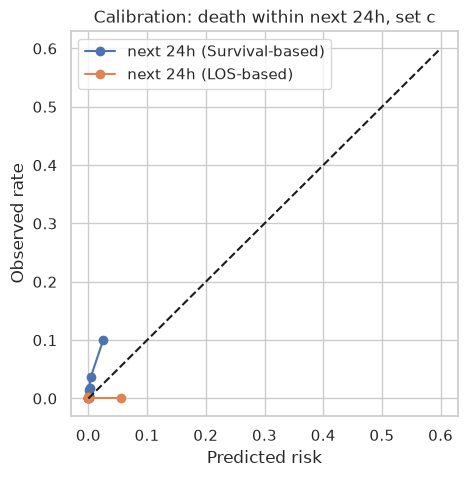

In [26]:
LANDMARKS = [6, 12, 18, 24, 30, 36, 42]
LIVER = ["ALP","ALT","AST","Bilirubin","Albumin"]

first_vent = ts[(ts.Parameter=="MechVent") & (ts.Value==1)].groupby("RecordID").minutes.min()/60
lab = df_out.set_index("RecordID")[["Survival","Length_of_stay"]]

parts = []
for T in LANDMARKS:
    tbl = landmark_table(T)
    tbl["T"] = T
    tbl["first_vent_h"] = tbl.RecordID.map(first_vent)
    tbl = tbl[tbl.first_vent_h <= T]                       # ventilated by landmark
    tbl["Survival"] = tbl.RecordID.map(lab.Survival)
    tbl["LOS"] = tbl.RecordID.map(lab.Length_of_stay)
    parts.append(tbl)
pool = pd.concat(parts, ignore_index=True)

# approximate death times (hours), only for patients who died
pool["dt_surv"] = np.where(pool.died==1, pool.Survival*24, np.inf)
pool["dt_los"]  = np.where(pool.died==1, pool.LOS*24, np.inf)

# still alive at landmark under both definitions
pool = pool[(pool.dt_surv > pool["T"]) & (pool.dt_los > pool["T"])].reset_index(drop=True)

pool["y_next24_surv"] = ((pool.dt_surv > pool["T"]) & (pool.dt_surv <= pool["T"]+24)).astype(int)
pool["y_next24_los"]  = ((pool.dt_los  > pool["T"]) & (pool.dt_los  <= pool["T"]+24)).astype(int)

print(pool.groupby("T").agg(n=("RecordID","size"), died=("died","mean"),
                            next24_surv=("y_next24_surv","mean"),
                            next24_los=("y_next24_los","mean")).round(3))

extra = ["first_vent_h","Survival","LOS","dt_surv","dt_los","y_next24_surv","y_next24_los"]
feat_cols = [c for c in pool.columns
             if c not in meta + extra
             and not c.endswith("_stale_h") and not c.endswith("_n")
             and base(c) not in LIVER]
print(len(feat_cols), "features (includes 'T' = landmark hour)")

tr = pool[pool.set.isin(["a","b"])]
te = pool[pool.set == "c"].reset_index(drop=True)

labels = {"in-hospital death": "died",
          "next 24h (Survival-based)": "y_next24_surv",
          "next 24h (LOS-based)": "y_next24_los"}

models, preds, rows = {}, {}, []
for name, ycol in labels.items():
    ps = []
    for s in range(3):
        m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.6,
                               random_state=s, verbose=-1)
        m.fit(tr[feat_cols], tr[ycol])
        ps.append(m.predict_proba(te[feat_cols])[:,1])
        if s == 0: models[name] = m
    preds[name] = np.mean(ps, axis=0)
    for T in LANDMARKS:
        i = (te["T"] == T).values
        y = te.loc[i, ycol].values
        rows.append(dict(label=name, T=T, n=i.sum(), events=y.sum(),
                         AUROC=roc_auc_score(y, preds[name][i]),
                         AUPRC=average_precision_score(y, preds[name][i]),
                         Brier=brier_score_loss(y, preds[name][i])))
    y = te[ycol].values
    rows.append(dict(label=name, T="all", n=len(te), events=y.sum(),
                     AUROC=roc_auc_score(y, preds[name]),
                     AUPRC=average_precision_score(y, preds[name]),
                     Brier=brier_score_loss(y, preds[name])))

display(pd.DataFrame(rows).round(3))

# calibration of the next-24h model (pooled over landmarks)
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(5,5))
for name in ["next 24h (Survival-based)", "next 24h (LOS-based)"]:
    fx, fy = calibration_curve(te[labels[name]], preds[name], n_bins=8, strategy="quantile")
    ax.plot(fy, fx, "o-", label=name)
mx = 0.6; ax.plot([0,mx],[0,mx],"k--")
ax.set_xlabel("Predicted risk"); ax.set_ylabel("Observed rate"); ax.legend()
ax.set_title("Calibration: death within next 24h, set c")

In [27]:
import shap
name = "in-hospital death"          # change to "next 24h (Survival-based)" if you prefer
m = models[name]
sv = shap.TreeExplainer(m).shap_values(te[feat_cols])
if isinstance(sv, list): sv = sv[1]
sv = np.asarray(sv)
if sv.ndim == 3: sv = sv[:, :, 1]

# one SHAP column per variable (features of one variable summed)
var_sv = pd.DataFrame(sv, columns=feat_cols).T.groupby(base).sum().T
te["risk"] = preds[name]

def what_changed(rid, T0, T1, k=3):
    a = te[(te.RecordID==rid) & (te["T"]==T0)]
    b = te[(te.RecordID==rid) & (te["T"]==T1)]
    if a.empty or b.empty: return None
    ia, ib = a.index[0], b.index[0]
    d = (var_sv.loc[ib] - var_sv.loc[ia]).drop("T", errors="ignore")
    top = d.reindex(d.abs().sort_values(ascending=False).index)[:k]
    parts = []
    for v, delta in top.items():
        c = f"{v}_last"
        if c in te:
            parts.append(f"{v} {a.loc[ia,c]:.3g} -> {b.loc[ib,c]:.3g} ({'raises' if delta>0 else 'lowers'} risk)")
        else:
            parts.append(f"{v} ({'raises' if delta>0 else 'lowers'} risk)")
    return (f"Patient {rid}: risk {a.risk.iloc[0]:.0%} at {T0}h -> {b.risk.iloc[0]:.0%} at {T1}h. "
            f"Changes: " + "; ".join(parts))

# patients with the largest 6h risk rise between 18h and 24h
a = te[te["T"]==18].set_index("RecordID").risk
b = te[te["T"]==24].set_index("RecordID").risk
jump = (b - a).dropna().sort_values(ascending=False)
for rid in jump.index[:5]:
    print(what_changed(rid, 18, 24), "| outcome:", "died" if te[te.RecordID==rid].died.iloc[0] else "survived")

Patient 160434: risk 36% at 18h -> 78% at 24h. Changes: Lactate 4.2 -> 11.5 (raises risk); GCS 9 -> 8 (raises risk); NIDiasABP nan -> 49 (raises risk) | outcome: survived
Patient 154984: risk 28% at 18h -> 61% at 24h. Changes: GCS 10 -> 3 (raises risk); Urine 25 -> 15 (raises risk); WBC 40.6 -> 36.6 (raises risk) | outcome: died
Patient 160581: risk 46% at 18h -> 77% at 24h. Changes: PaO2 nan -> 67 (raises risk); HR 97 -> 93 (raises risk); GCS 10 -> 8 (raises risk) | outcome: died
Patient 161783: risk 8% at 18h -> 36% at 24h. Changes: GCS 10 -> 3 (raises risk); PaO2 96 -> 96 (raises risk); Urine 70 -> 35 (raises risk) | outcome: died
Patient 155380: risk 15% at 18h -> 43% at 24h. Changes: GCS 15 -> 8 (raises risk); ICUType (raises risk); DiasABP nan -> 55 (raises risk) | outcome: survived


In [28]:
EXCL = ["Age","Gender","ICUType","Weight","T"]

def what_changed(rid, T0, T1, k=3, min_rel=0.10):
    a = te[(te.RecordID==rid) & (te["T"]==T0)]
    b = te[(te.RecordID==rid) & (te["T"]==T1)]
    if a.empty or b.empty: return None
    ia, ib = a.index[0], b.index[0]
    d = (var_sv.loc[ib] - var_sv.loc[ia]).drop(EXCL, errors="ignore")
    d = d.reindex(d.abs().sort_values(ascending=False).index)
    parts, newly = [], []
    for v, delta in d.items():
        c = f"{v}_last"
        if c not in te: continue
        x0, x1 = a.loc[ia, c], b.loc[ib, c]
        if pd.isna(x1): continue
        if pd.isna(x0): newly.append(v); continue
        if abs(x1 - x0) < min_rel * max(abs(x0), 1e-9): continue   # skip trivial changes
        if len(parts) < k:
            parts.append(f"{v} {x0:.3g} -> {x1:.3g} ({'raises' if delta>0 else 'lowers'} risk)")
    s = (f"Patient {rid}: risk {a.risk.iloc[0]:.0%} at {T0}h -> {b.risk.iloc[0]:.0%} at {T1}h. "
         f"Changes: " + "; ".join(parts))
    return s + (f". Newly measured: {', '.join(newly[:3])}" if newly else "")

for rid in jump.index[:5]:
    print(what_changed(rid, 18, 24), "| outcome:", "died" if te[te.RecordID==rid].died.iloc[0] else "survived")

Patient 160434: risk 36% at 18h -> 78% at 24h. Changes: Lactate 4.2 -> 11.5 (raises risk); GCS 9 -> 8 (raises risk); HCO3 21 -> 14 (raises risk). Newly measured: NIDiasABP, NIMAP, TroponinT | outcome: survived
Patient 154984: risk 28% at 18h -> 61% at 24h. Changes: GCS 10 -> 3 (raises risk); Urine 25 -> 15 (raises risk); SysABP 87 -> 101 (raises risk). Newly measured: SaO2 | outcome: died
Patient 160581: risk 46% at 18h -> 77% at 24h. Changes: GCS 10 -> 8 (raises risk); Urine 60 -> 20 (lowers risk); NIDiasABP 63 -> 55 (lowers risk). Newly measured: PaO2, PaCO2, SaO2 | outcome: died
Patient 161783: risk 8% at 18h -> 36% at 24h. Changes: GCS 10 -> 3 (raises risk); Urine 70 -> 35 (raises risk); SysABP 126 -> 102 (lowers risk) | outcome: died
Patient 155380: risk 15% at 18h -> 43% at 24h. Changes: GCS 15 -> 8 (raises risk); FiO2 1 -> 0.8 (raises risk); HR 125 -> 66 (lowers risk). Newly measured: DiasABP, PaCO2, PaO2 | outcome: survived


In [29]:
LABS_D = [l for l in ["Lactate","PaO2","PaCO2","pH","Creatinine","BUN","WBC","Platelets",
                      "HCO3","Glucose","K","Na","Mg","HCT","SaO2","TroponinT"]]
VALS = ["last","mean","mn","mx","w_mean"]

trA = pool[pool.set=="a"].reset_index(drop=True)
vaB = pool[pool.set=="b"].reset_index(drop=True)
trAB = pool[pool.set.isin(["a","b"])].reset_index(drop=True)
teC = pool[pool.set=="c"].reset_index(drop=True)

med = {l: trA[f"{l}_last"].median() for l in LABS_D}      # medians from training data only

def decay(df, tau):
    df = df.copy()
    if tau is None: return df
    for l in LABS_D:
        w = np.exp(-df[f"{l}_stale_h"] / tau)
        for k in VALS:
            c = f"{l}_{k}"
            if c in df: df[c] = med[l] + (df[c] - med[l]) * w
        if f"{l}_slope6" in df: df[f"{l}_slope6"] = df[f"{l}_slope6"] * w
    return df

def fit_pred(tr, te, tau, seeds=2):
    Xtr, Xte = decay(tr, tau)[feat_cols], decay(te, tau)[feat_cols]
    ps = []
    for s in range(seeds):
        m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.6,
                               random_state=s, verbose=-1)
        m.fit(Xtr, tr.died)
        ps.append(m.predict_proba(Xte)[:,1])
    return np.mean(ps, axis=0)

# 1) tune tau on validation set b
val = []
for tau in [3, 6, 12, 24, 48, None]:
    p = fit_pred(trA, vaB, tau)
    val.append(dict(tau=tau if tau else "none", AUROC=roc_auc_score(vaB.died, p),
                    AUPRC=average_precision_score(vaB.died, p)))
val = pd.DataFrame(val); display(val.round(4))

best = val[val.tau != "none"].sort_values("AUROC", ascending=False).iloc[0]
best_tau = float(best.tau); print("Chosen tau (validation):", best_tau)

# 2) single evaluation on test set c
P_ref = fit_pred(trAB, teC, None, seeds=3)
P_dec = fit_pred(trAB, teC, best_tau, seeds=3)
y = teC.died.values
print(f"plain forward-fill : AUROC {roc_auc_score(y,P_ref):.4f}  AUPRC {average_precision_score(y,P_ref):.4f}")
print(f"soft decay tau={best_tau:g}: AUROC {roc_auc_score(y,P_dec):.4f}  AUPRC {average_precision_score(y,P_dec):.4f}")

# 3) patient-level paired bootstrap
idx = teC.groupby("RecordID").indices
keys = np.array(list(idx.keys()))
rng = np.random.default_rng(0)
da, dp = [], []
for _ in range(500):
    i = np.concatenate([idx[k] for k in rng.choice(keys, len(keys))])
    da.append(roc_auc_score(y[i], P_dec[i]) - roc_auc_score(y[i], P_ref[i]))
    dp.append(average_precision_score(y[i], P_dec[i]) - average_precision_score(y[i], P_ref[i]))
for n, d in [("AUROC", da), ("AUPRC", dp)]:
    print(f"soft decay effect on {n}: {np.mean(d):+.4f}  95% CI [{np.percentile(d,2.5):+.4f}, {np.percentile(d,97.5):+.4f}]")

,tau,AUROC,AUPRC
0,3,0.8229,0.4627
1,6,0.8236,0.4647
2,12,0.8238,0.4566
3,24,0.8250,0.4596
4,48,0.8238,0.4572
5,none,0.8226,0.4564


Chosen tau (validation): 24.0
plain forward-fill : AUROC 0.8475  AUPRC 0.5264
soft decay tau=24: AUROC 0.8453  AUPRC 0.5153
soft decay effect on AUROC: -0.0022  95% CI [-0.0054, +0.0008]
soft decay effect on AUPRC: -0.0111  95% CI [-0.0205, -0.0021]
